In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

ratings = pd.read_csv("../data/ml-32m/ratings.csv")
movies  = pd.read_csv("../data/ml-32m/movies.csv")
links   = pd.read_csv("../data/ml-32m/links.csv")

print("Ratings:", ratings.shape)
print("Movies:", movies.shape)
print("Links:", links.shape)

print(ratings.head())

Ratings: (32000204, 4)
Movies: (87585, 3)
Links: (87585, 3)
   userId  movieId  rating  timestamp
0       1       17     4.0  944249077
1       1       25     1.0  944250228
2       1       29     2.0  943230976
3       1       30     5.0  944249077
4       1       32     5.0  943228858


count    200948.000000
mean        159.246193
std         282.025462
min          20.000000
25%          36.000000
50%          73.000000
75%         167.000000
max       33332.000000
dtype: float64
20+ ratings: 200,948 users
30+ ratings: 166,757 users
50+ ratings: 128,344 users
75+ ratings: 98,697 users
100+ ratings: 80,675 users
200+ ratings: 42,197 users
500+ ratings: 12,603 users


Text(0, 0.5, 'Number of Users (log scale)')

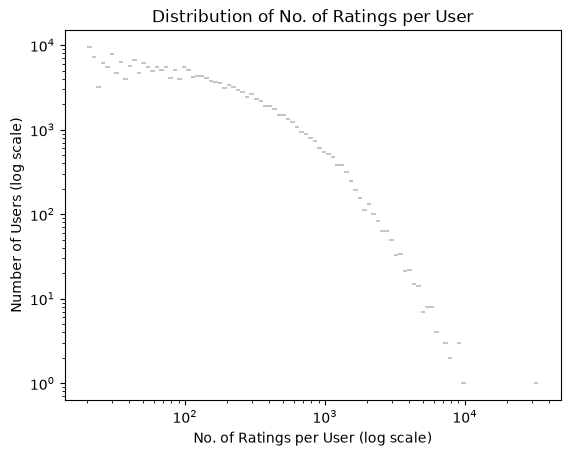

In [3]:
ratings_per_user = ratings.groupby("userId").size()

print(ratings_per_user.describe())

for threshold in [20, 30, 50, 75, 100, 200, 500]:
    n_users = (ratings_per_user >= threshold).sum()
    print(f"{threshold}+ ratings: {n_users:,} users")

sns.histplot(ratings_per_user, bins=100, log_scale=(True, True))
plt.title("Distribution of No. of Ratings per User")
plt.xlabel("No. of Ratings per User (log scale)")
plt.ylabel("Number of Users (log scale)")

Filtered User Ratings: (263586, 4)
Train Ratings: (210868, 4)
Test Ratings: (52718, 4)
       userId  movieId  rating   timestamp
14669      94       39     3.5  1663972862
14670      94       92     4.5  1663974472
14671      94      107     4.0  1663974072
14672      94      111     3.0  1663969727
14673      94      162     4.0  1663970900

               userId        movieId         rating     timestamp
count  263586.000000  263586.000000  263586.000000  2.635860e+05
mean   102147.983755   27562.615131       3.575516  1.275112e+09
std     57508.408820   48453.735652       1.033159  2.506300e+08
min        94.000000       1.000000       0.500000  8.296954e+08
25%     52183.000000    1270.000000       3.000000  1.047559e+09
50%    104027.000000    3421.000000       4.000000  1.249070e+09
75%    149550.000000   37733.000000       4.000000  1.503225e+09
max    200679.000000  292365.000000       5.000000  1.696822e+09

Ratings per Filtered User:
 count    1000.000000
mean      263.5860

Text(0, 0.5, 'Number of Users')

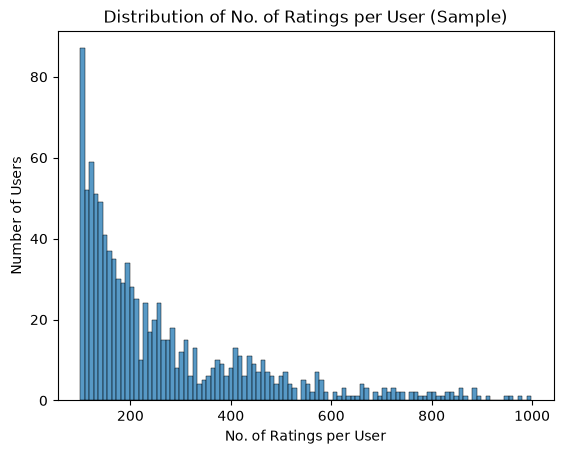

In [4]:
#sample
# previously filtered between 50 and 1000
filtered_users = ratings_per_user[(ratings_per_user >= 100) & (ratings_per_user <= 1000)]
filtered_users_sample = filtered_users.sample(n=1000, random_state=1)

#pipeline test
filtered_users_sample2 = filtered_users[
    ~filtered_users.index.isin(filtered_users_sample.index)
].sample(n=1000, random_state=1)

filtered_ratings = ratings[ratings["userId"].isin(filtered_users_sample.index)]

# export filtered ratings 2 to pipeline
filtered_ratings2 = ratings[ratings["userId"].isin(filtered_users_sample2.index)]
filtered_ratings2.to_csv(
    "../data/filtered_ratings2.csv",
    index=False
)

train_ratings, test_ratings = train_test_split(
    filtered_ratings,
    test_size=0.2,
    random_state=42,
)

print("Filtered User Ratings:", filtered_ratings.shape)
print("Train Ratings:", train_ratings.shape)
print("Test Ratings:", test_ratings.shape)
print(filtered_ratings.head())
print("\n", filtered_ratings.describe())

#export training/test ratings to do ndcg eval
train_ratings.to_csv(
    "../data/train_ratings.csv",
    index=False
)
test_ratings.to_csv(
    "../data/test_ratings.csv",
    index=False
)

#per user data
ratings_per_filtered_user = filtered_ratings.groupby("userId").size()
print("\nRatings per Filtered User:\n", ratings_per_filtered_user.describe())

sns.histplot(ratings_per_filtered_user, bins=100, log_scale=(False, False))
plt.title("Distribution of No. of Ratings per User (Sample)")
plt.xlabel("No. of Ratings per User")
plt.ylabel("Number of Users")


Text(0, 0.5, 'Number of Users')

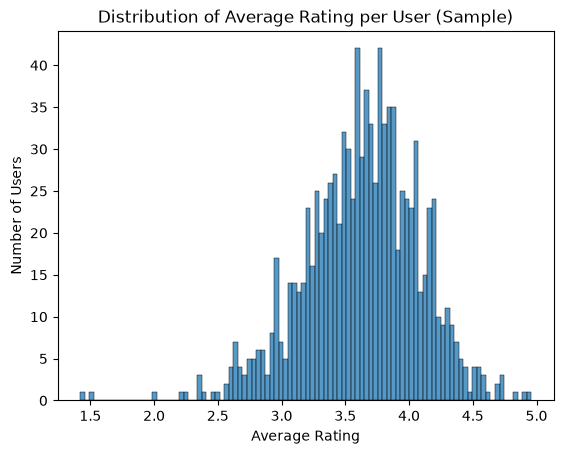

In [5]:
#plot user average rating 
#to be standardised (normalised?)
user_average_ratings = filtered_ratings.groupby("userId")["rating"].mean()

sns.histplot(user_average_ratings, bins=100, log_scale=(False, False))
plt.title("Distribution of Average Rating per User (Sample)")
plt.xlabel("Average Rating")
plt.ylabel("Number of Users")

#plot genre average?

In [6]:
#movies filter
selected_movies_id = train_ratings["movieId"].unique()
movies_filtered = movies[movies["movieId"].isin(selected_movies_id)]

print("Filtered Movies:", movies_filtered.shape[0])

Filtered Movies: 12266


In [7]:
genre_encoded = movies_filtered["genres"].str.get_dummies(sep="|")

movies_encoded = pd.concat(
    [movies_filtered, genre_encoded],
    axis=1,
)

movies_encoded = movies_encoded.drop(columns=["genres", "(no genres listed)"])

print(movies_encoded.head())

   movieId                               title  Action  Adventure  Animation  \
0        1                    Toy Story (1995)       0          1          1   
1        2                      Jumanji (1995)       0          1          0   
2        3             Grumpier Old Men (1995)       0          0          0   
3        4            Waiting to Exhale (1995)       0          0          0   
4        5  Father of the Bride Part II (1995)       0          0          0   

   Children  Comedy  Crime  Documentary  Drama  ...  Film-Noir  Horror  IMAX  \
0         1       1      0            0      0  ...          0       0     0   
1         1       0      0            0      0  ...          0       0     0   
2         0       1      0            0      0  ...          0       0     0   
3         0       1      0            0      1  ...          0       0     0   
4         0       1      0            0      0  ...          0       0     0   

   Musical  Mystery  Romance  Sci-Fi  

In [8]:
#clean title and extract release year

movies_encoded["Release_Year"] = (movies_encoded["title"].str.extract(r"\((\d{4})\)$")[0])
movies_encoded["Release_Year"] = pd.to_numeric(movies_encoded["Release_Year"], errors="coerce")
movies_encoded["title_clean"] = (movies_encoded["title"].str.replace(r"\s*\(\d{4}\)$", "", regex=True))
movies_encoded = movies_encoded.drop(columns=["title"])

print(movies_encoded.shape)
print(movies_encoded.head())

(12266, 22)
   movieId  Action  Adventure  Animation  Children  Comedy  Crime  \
0        1       0          1          1         1       1      0   
1        2       0          1          0         1       0      0   
2        3       0          0          0         0       1      0   
3        4       0          0          0         0       1      0   
4        5       0          0          0         0       1      0   

   Documentary  Drama  Fantasy  ...  IMAX  Musical  Mystery  Romance  Sci-Fi  \
0            0      0        1  ...     0        0        0        0       0   
1            0      0        1  ...     0        0        0        0       0   
2            0      0        0  ...     0        0        0        1       0   
3            0      1        0  ...     0        0        0        1       0   
4            0      0        0  ...     0        0        0        0       0   

   Thriller  War  Western  Release_Year                  title_clean  
0         0    0     

In [9]:
#add avg rating to movie feature matrix

avg_ratings = train_ratings.groupby("movieId")["rating"].mean().rename("avg_rating")
movies_encoded = movies_encoded.merge(avg_ratings, on="movieId", how="left")

print(movies_encoded.head())

   movieId  Action  Adventure  Animation  Children  Comedy  Crime  \
0        1       0          1          1         1       1      0   
1        2       0          1          0         1       0      0   
2        3       0          0          0         0       1      0   
3        4       0          0          0         0       1      0   
4        5       0          0          0         0       1      0   

   Documentary  Drama  Fantasy  ...  Musical  Mystery  Romance  Sci-Fi  \
0            0      0        1  ...        0        0        0       0   
1            0      0        1  ...        0        0        0       0   
2            0      0        0  ...        0        0        1       0   
3            0      1        0  ...        0        0        1       0   
4            0      0        0  ...        0        0        0       0   

   Thriller  War  Western  Release_Year                  title_clean  \
0         0    0        0        1995.0                    Toy Story

In [10]:
# testing decade
movies_encoded["Decade"] = (movies_encoded["Release_Year"] // 10) * 10
decade_avg_ratings = movies_encoded.groupby("Decade")["avg_rating"].mean().rename("decade_avg_rating")

print("\nDecade Average Ratings:\n", decade_avg_ratings)



Decade Average Ratings:
 Decade
1890.0    3.500000
1900.0    3.825000
1910.0    3.535714
1920.0    3.743204
1930.0    3.555744
1940.0    3.650629
1950.0    3.619171
1960.0    3.657223
1970.0    3.602290
1980.0    3.362546
1990.0    3.276391
2000.0    3.293347
2010.0    3.429175
2020.0    3.422551
Name: decade_avg_rating, dtype: float64


In [11]:
#one hot encode movie decades 
movies_encoded = pd.get_dummies(movies_encoded, columns=["Decade"], dtype = int)

print(movies_encoded.head())

print("\n", movies_encoded.columns.tolist())

   movieId  Action  Adventure  Animation  Children  Comedy  Crime  \
0        1       0          1          1         1       1      0   
1        2       0          1          0         1       0      0   
2        3       0          0          0         0       1      0   
3        4       0          0          0         0       1      0   
4        5       0          0          0         0       1      0   

   Documentary  Drama  Fantasy  ...  Decade_1930.0  Decade_1940.0  \
0            0      0        1  ...              0              0   
1            0      0        1  ...              0              0   
2            0      0        0  ...              0              0   
3            0      1        0  ...              0              0   
4            0      0        0  ...              0              0   

   Decade_1950.0  Decade_1960.0  Decade_1970.0  Decade_1980.0  Decade_1990.0  \
0              0              0              0              0              1   
1         

In [12]:
#enrich movie feature matrix with TMDB extra features
#already preprocessed in the TMDB data collection notebooks

tmdb_data = np.load("../data/tmdb_movie_features.npz")

tmdb_ids = tmdb_data["movie_ids"]
tmdb_features = tmdb_data["features"]

tmdb_df = pd.DataFrame(
    tmdb_features,
    columns=[f"tmdb_{i}" for i in range(tmdb_features.shape[1])]
)

tmdb_df["movieId"] = tmdb_ids

movies_encoded = movies_encoded.merge(
    tmdb_df,
    on="movieId",
    how="left"
)


In [13]:
#export movies to move to backend for displaying recs
movies_encoded.to_parquet(
    "../data/movie_catalogue.parquet",
    index=False
)


In [ ]:
#build the feature matrix for users (avg ratings by genre)

users_encoded = pd.DataFrame(index=filtered_users_sample.index)

users_encoded.index.name = "userId"

genre_columns = genre_encoded.columns.tolist()
genre_columns.remove("(no genres listed)")

movies_encoded_by_id = movies_encoded.set_index("movieId")

for genre in genre_columns:
    #average of ratings for movies by genre for filtered users
    genre_movie_ids = movies_encoded_by_id.index[movies_encoded_by_id[genre] == 1]

    users_encoded[genre] = train_ratings[train_ratings["movieId"].isin(genre_movie_ids)].groupby("userId")["rating"].mean()



print(users_encoded.head())

         Action  Adventure  Animation  Children  Comedy  Crime  Documentary  \
movieId                                                                       
1             0          1          1         1       1      0            0   
2             0          1          0         1       0      0            0   
3             0          0          0         0       1      0            0   
4             0          0          0         0       1      0            0   
5             0          0          0         0       1      0            0   

         Drama  Fantasy  Film-Noir  ...  tmdb_551  tmdb_552  tmdb_553  \
movieId                             ...                                 
1            0        1          0  ... -0.031209  0.126908  0.182608   
2            0        1          0  ... -0.042879 -0.048587  0.145591   
3            0        0          0  ... -0.071053 -0.019773 -0.044829   
4            1        0          0  ... -0.095144 -0.011351 -0.162661   
5       

In [15]:
#user feature matrix with decade average ratings

decade_columns = [
    col for col in movies_encoded.columns if col.startswith("Decade_")
]

for decade in decade_columns:
    #average of ratings for movies by decade for filtered users
    decade_movie_ids = movies_encoded_by_id.index[movies_encoded_by_id[decade] == 1]

    users_encoded[decade] = train_ratings[train_ratings["movieId"].isin(decade_movie_ids)].groupby("userId")["rating"].mean()

print(users_encoded.head())
print("\n", users_encoded.columns.tolist())

          Action  Adventure  Animation  Children    Comedy     Crime  \
userId                                                                 
82082   1.600000   1.970000   2.269231  2.000000  2.893333  2.411765   
139773  2.809524   3.263158   3.500000  3.500000  3.454545  3.176471   
130249  3.009259   2.959677   3.017857  2.946429  3.073529  3.738095   
31987   3.089041   3.205128   4.000000  2.833333  3.033333  3.140000   
45359   3.597222   3.642857   3.500000  3.500000  4.382353  4.069767   

        Documentary     Drama   Fantasy  Film-Noir  ...  Decade_1930.0  \
userId                                              ...                  
82082           NaN  3.254717  1.467742        NaN  ...            NaN   
139773          NaN  3.576271  3.333333        NaN  ...            NaN   
130249          NaN  3.468750  2.932432        5.0  ...            NaN   
31987      3.000000  3.333333  3.500000        3.5  ...            NaN   
45359      3.833333  4.317073  3.923077        NaN 

In [16]:
# add user features - avg rating, std rating, count of ratings
users_encoded["avg_rating"] = train_ratings.groupby("userId")["rating"].mean()
users_encoded["std_rating"] = train_ratings.groupby("userId")["rating"].std()
users_encoded["count_rating"] = train_ratings.groupby("userId")["rating"].count()

In [17]:
#build combined table 
user_features = users_encoded.reset_index().rename(
    columns={
        col: f"user_{col}" 
        for col in users_encoded.columns})

movie_features = movies_encoded.rename(
    columns={
        col: f"movie_{col}" 
        for col in movies_encoded.columns 
        if col != "movieId"})

training_data = train_ratings.merge(user_features, on="userId", how="left")
training_data = training_data.merge(movie_features, on="movieId", how="left")

test_data = test_ratings.merge(user_features, on="userId", how="left")
test_data = test_data.merge(movie_features, on="movieId", how="left")


In [18]:
#build genre affinity for xgboost 
user_genre_cols = [f"user_{genre}" for genre in genre_columns]
movie_genre_cols = [f"movie_{genre}" for genre in genre_columns]

user_genre_values = (
    training_data[user_genre_cols]
    .fillna(0)
    .to_numpy()
)
movie_genre_values = (
    training_data[movie_genre_cols]
    .fillna(0)
    .to_numpy()
)
training_data["genre_affinity"] = np.divide(
    (user_genre_values * movie_genre_values).sum(axis=1), 
    movie_genre_values.sum(axis=1),
    out=np.full(len(training_data), np.nan),
    where=movie_genre_values.sum(axis=1) != 0
)

user_genre_values_test = (
    test_data[user_genre_cols]
    .fillna(0)
    .to_numpy()
)
movie_genre_values_test = (
    test_data[movie_genre_cols]
    .fillna(0)
    .to_numpy()
)
test_data["genre_affinity"] = np.divide(
    (user_genre_values_test * movie_genre_values_test).sum(axis=1),
    movie_genre_values_test.sum(axis=1),
    out=np.full(len(test_data), np.nan),
    where=movie_genre_values_test.sum(axis=1) != 0
)

# build decade affinity
user_decade_cols = [f"user_{decade}" for decade in decade_columns]
movie_decade_cols = [f"movie_{decade}" for decade in decade_columns]

user_decade_values = (
    training_data[user_decade_cols]
    .fillna(0)
    .to_numpy()
)
movie_decade_values = (
    training_data[movie_decade_cols]
    .fillna(0)
    .to_numpy()
)
training_data["decade_affinity"] = np.divide(
    (user_decade_values * movie_decade_values).sum(axis=1), 
    movie_decade_values.sum(axis=1),
    out=np.full(len(training_data), np.nan),
    where=movie_decade_values.sum(axis=1) != 0
)

user_decade_values_test = (
    test_data[user_decade_cols]
    .fillna(0)
    .to_numpy()
)
movie_decade_values_test = (
    test_data[movie_decade_cols]
    .fillna(0)
    .to_numpy()
)
test_data["decade_affinity"] = np.divide(
    (user_decade_values_test * movie_decade_values_test).sum(axis=1),
    movie_decade_values_test.sum(axis=1),
    out=np.full(len(test_data), np.nan),
    where=movie_decade_values_test.sum(axis=1) != 0
)

print("Training Data:", training_data.shape)
print("Test Data:", test_data.shape)
print(training_data.head())
print("\n", training_data.columns.tolist())

Training Data: (210868, 639)
Test Data: (52718, 639)
   userId  movieId  rating   timestamp  user_Action  user_Adventure  \
0  195675     6001     3.5  1557391988     3.500000        3.636364   
1   55633     7007     5.0  1511293786     3.633333        2.650000   
2   64825     4993     5.0  1133928001     3.744186        3.920455   
3   63615     3744     4.0  1083356242     3.528912        3.439597   
4  130249     3114     2.5  1687613215     3.009259        2.959677   

   user_Animation  user_Children  user_Comedy  user_Crime  ...  \
0        3.636364       3.416667     3.958333    3.979167  ...   
1        0.545455       0.781250     2.919753    4.147541  ...   
2        4.230769       3.812500     3.464286    3.937500  ...   
3        2.970588       2.970588     3.152542    3.333333  ...   
4        3.017857       2.946429     3.073529    3.738095  ...   

   movie_tmdb_553  movie_tmdb_554  movie_tmdb_555  movie_tmdb_556  \
0       -0.041469       -0.000884       -0.181904     

In [19]:
#export for ndcg eval
training_data.to_csv(
    "../data/training_data.csv",
    index=False
)

# export for ndcg eval
test_data.to_csv(
    "../data/test_data.csv",
    index=False
)

In [20]:
#set X and Y
user_cols = ["user_" + col for col in users_encoded.columns]
#export user_cols list
np.save("../data/user_cols.npy", user_cols)

movie_cols = ["movie_" + col 
              for col in movies_encoded.columns
              if col not in ["movieId", "title_clean", "Release_Year"]
              ]
#export movie_cols list
np.save("../data/movie_cols.npy", movie_cols)

X_user_train = training_data[user_cols]
X_movie_train = training_data[movie_cols]
y_train = training_data["rating"]

X_user_test = test_data[user_cols]
X_movie_test = test_data[movie_cols]
y_test = test_data["rating"]

#temp user for testing backend pipeline
test_user_id = test_data["userId"].iloc[0]
print("Test User ID:", test_user_id)
watched_movie_ids = pd.concat([
    training_data[training_data["userId"] == test_user_id]["movieId"],
    test_data[test_data["userId"] == test_user_id]["movieId"]
]).tolist()
print("Watched Movie IDs:", watched_movie_ids)

print("X_user_train shape:", X_user_train.shape)
print("X_movie_train shape:", X_movie_train.shape)
print("y_train shape:", y_train.shape)
print("X_user_test shape:", X_user_test.shape)
print("X_movie_test shape:", X_movie_test.shape)
print("y_test shape:", y_test.shape)

print("\n", X_user_train.columns.tolist())
print("\n", X_movie_train.columns.tolist())


Test User ID: 129967
Watched Movie IDs: [31696, 3996, 4700, 3564, 33639, 2640, 3984, 3921, 3452, 2687, 4248, 2321, 1271, 2424, 5303, 524, 9000, 6294, 3639, 4447, 2581, 8525, 2145, 4446, 6593, 8665, 410, 551, 5943, 4387, 500, 743, 7303, 262, 3857, 8970, 26680, 4069, 838, 2759, 3005, 5103, 1356, 2405, 2273, 8360, 5629, 1544, 1223, 4141, 2805, 945, 637, 2089, 8833, 1377, 31685, 597, 8989, 360, 5530, 4036, 2915, 7000, 914, 5168, 4886, 2150, 2168, 3552, 3363, 2723, 4177, 2947, 1610, 590, 2644, 364, 2804, 879, 1888, 440, 4621, 7046, 955, 903, 2057, 3578, 3688, 38038, 6357, 1269, 329, 1031, 466, 3301, 3034, 6791, 1014, 4068, 926, 4857, 36401, 2052, 1381, 5047, 12, 270, 17, 2940, 2105, 902, 37729, 8808, 2094, 5375, 2115, 2877, 2431, 1086, 5309, 235, 6996, 3033, 1876, 3481, 1022, 5460, 4299, 2643, 7361, 1380, 317, 596, 2571, 3882, 3671, 4639, 3248, 6373, 1285, 7165, 5452, 1198, 5620, 8865, 3546, 1681, 45517, 4862, 7822, 2087, 1453, 8949, 2396, 1291, 6252, 7369, 160, 1033, 207, 6874, 7614, 7, 40

In [21]:
#Irrelevant to training model
#test backend pipeline with temp user
test_user = X_user_test.iloc[[0]]

test_user.to_csv("../data/test_user.csv", index=False)

In [22]:
#export the feature matrices to CSV files
X_user_train.to_csv(
    "../data/X_user_train.csv",
    index=False
)

X_movie_train.to_csv(
    "../data/X_movie_train.csv",
    index=False
)

y_train.to_csv(
    "../data/y_train.csv",
    index=False
)

X_user_test.to_csv(
    "../data/X_user_test.csv",
    index=False
)

X_movie_test.to_csv(
    "../data/X_movie_test.csv",
    index=False
)

y_test.to_csv(
    "../data/y_test.csv",
    index=False
)

In [23]:
#recency weighting rating*beta/beta, beta > 1 for ratings in the most recent year